# <font color='#2E86C1' size=6>**Outlier detection**</font>

**Workflow:** [01 Data cleaning](01_data_cleaning.ipynb) → [02 Customer table](02_customer_table.ipynb) → [03 Missing values](03_missing_values.ipynb) → **04 Outliers** → [05 Pipeline and models](05_preprocessing_and_models.ipynb) → [06 Feature engineering and selection](06_feature_engineering_selection.ipynb)

This notebook decides how unusual values should be handled in this project. The decision is based on data meaning and temporal cross-validation, not only on how many rows an algorithm flags.

## Table of Contents <a class="anchor" id="toc"></a>
- [0. Imports and configuration](#imports)
- [1. Load the cleaned development data](#load)
- [2. Separate data errors from valid extremes](#errors)
- [3. Numerical overview](#overview)
- [4. IQR and skewness report](#iqr)
- [5. Inspect the strongest values](#inspect)
- [6. What do the algorithms actually flag?](#flags)
- [7. Temporal validation setup](#cv)
- [8. Compare transformations](#transformations)
- [9. Compare row-removal methods](#removal)
- [10. DBSCAN sensitivity](#dbscan)
- [11. Method-by-method judgement](#judgement)
- [Final decision](#decision)

**Evaluation protocol (2026-11-15):** history is frozen inside each fit at its last training date. Validation/embargo/locked-period purchases cannot supply that fit's history. Lookup IDs/dates are excluded from model inputs. Earlier numerical interpretations based on the 2SE rule are withdrawn.

**Comparison policy:** paired differences are descriptive. We report the mean, standard deviation, range and folds won. Overlapping temporal folds are dependent: these are not confidence intervals or significance tests. `consistent_gain` means strict improvement on every fold (at least two), a conservative screening heuristic; magnitude, domain reasoning and complexity still matter.

**Verified execution (2026-11-15):** 13/13 code cells executed with the corrected protocol. Full execution.


## Principles

- An impossible value is a data error and is handled by a consistency rule.
- An extreme value is not automatically an error. Large purchases and long customer histories may be valid.
- The most recent 20% of the training period remains locked and is not used to choose a method.
- Transformations and outlier detectors are fitted on each training fold only. Validation rows are never removed.
- Rows from `test.csv` are never removed.

# <font color='#2E86C1' size=6>**0. Imports and configuration**</font> <a class="anchor" id="imports"></a>

[Back to TOC](#toc)

In [1]:
import os
import sys
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from minisom import MiniSom
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import DBSCAN, KMeans
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

import classification.preprocessing as classification_prep
import regression.preprocessing as regression_prep
from classification.model import build_model as build_classifier
from regression.model import build_model as build_regressor
from src.cleaning import drop_training_rows, prepare_table
from src.data import load_data, standardize_columns
from src.evaluate import cross_validate_pipeline, paired_comparison, select_scoring, temporal_folds
from src.pipeline import build_pipeline as build_model_pipeline, prepare_task_data
from src.preprocessing import build_preprocessor, split_dev_test, task_preprocessing_config
from src.tasks import TASKS

warnings.filterwarnings("ignore")

with open("config.yaml", encoding="utf-8") as file:
    config = yaml.safe_load(file)

data_cfg = config["data"]
diag_cfg = config["diagnostics"]
SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}

# <font color='#2E86C1' size=6>**1. Load the cleaned development data**</font> <a class="anchor" id="load"></a>

The same project functions used by `main.py` apply the cleaning rules. The 65 almost-empty rows are removed. The recent locked period is set aside before any outlier decision is made.

[Back to TOC](#toc)

In [2]:
train_raw = load_data(data_cfg["train_path"])
test_raw = load_data(data_cfg["test_path"])
clientes_raw = load_data(data_cfg["clientes_path"])

train_clean, cleaning_report = prepare_table(
    train_raw, config, clientes_raw
)
train_clean, row_report = drop_training_rows(
    train_clean, diag_cfg, data_cfg["id_column"], config["customers"]
)

classification_rows = classification_prep.select_training_rows(
    train_clean, config
)
X, y, extras = classification_prep.prepare_features(
    classification_rows, config
)
X_dev, X_locked, y_dev, y_locked, extras_dev, extras_locked = (
    split_dev_test(
        X, y, extras, config["test_set"], data_cfg["date_column"]
    )
)

print("Raw training rows:", len(train_raw))
print("Rows after cleaning:", len(train_clean))
print("Development rows analysed:", len(X_dev))
print("Locked rows not analysed:", len(X_locked))

Raw training rows: 6534
Rows after cleaning: 6469
Development rows analysed: 5024
Locked rows not analysed: 1286


# <font color='#2E86C1' size=6>**2. Separate data errors from valid extremes**</font> <a class="anchor" id="errors"></a>

A previous maximum purchase cannot be larger than the sum of all previous purchases. This is a logical error, not a statistical outlier. The rule is now in `config.yaml`; invalid values become missing and the fitted median imputer handles them inside each fold.

[Back to TOC](#toc)

In [3]:
def count_impossible_prior_max(raw_data):
    data = standardize_columns(raw_data, diag_cfg["column_renames"])
    is_error = (
        data["prior_purchase_count"].gt(0)
        & data["prior_max_purchase_value"].notna()
        & data["prior_total_spend"].notna()
        & data["prior_max_purchase_value"].gt(
            data["prior_total_spend"] + 0.01
        )
    )
    return int(is_error.sum())

print("Impossible values in train:", count_impossible_prior_max(train_raw))
print("Impossible values in test: ", count_impossible_prior_max(test_raw))

Impossible values in train: 45
Impossible values in test:  6


# <font color='#2E86C1' size=6>**3. Numerical overview**</font> <a class="anchor" id="overview"></a>

Targets, identifiers and dates are excluded. Only numerical predictors used by the classification recipe are inspected here.

[Back to TOC](#toc)

In [4]:
classification_cfg = task_preprocessing_config(config, "classification")
numeric_columns = [
    column for column in classification_cfg["numeric_features"]
    if column in X_dev.columns
]
numeric_data = X_dev[numeric_columns].copy()

print("Numerical columns analysed:", len(numeric_columns))
display(numeric_data.describe().T)

Numerical columns analysed: 23


,count,mean,std,min,25%,50%,75%,max
net_total,5024.0,698.927054,1004.933133,0.76,141.15,357.23,825.0125,11734.48
total_tax,5024.0,138.855016,192.953552,0.0,27.705,74.555,171.395,2698.93
line_discount_total,5024.0,91.684156,253.479282,0.0,0.0,7.455,71.975,3794.51
cost,5024.0,296.356923,452.033447,0.0,43.73,141.038285,360.846419,6111.3
line_item_count,5024.0,20.553145,27.303472,1.0,3.0,10.0,27.0,423.0
days_since_previous_purchase,5018.0,89.999801,154.171054,0.0,9.0,42.0,112.0,2524.0
customer_tenure_days,5024.0,866.080016,731.970515,0.0,230.75,737.0,1391.5,2806.0
prior_purchase_count,5024.0,20.160828,36.067294,0.0,2.0,8.0,22.0,262.0
prior_total_spend,5024.0,14355.662631,22711.413634,0.0,1101.84,5202.235,16942.2675,196270.66
prior_mean_purchase_value,5024.0,736.974902,729.760349,0.0,219.573885,597.787703,965.440499,6685.165


# <font color='#2E86C1' size=6>**4. IQR and skewness report**</font> <a class="anchor" id="iqr"></a>

The IQR rule is a useful warning signal, not a deletion rule. It is not informative when the IQR is zero, which happens in sparse or almost-constant columns.

[Back to TOC](#toc)

In [5]:
report_rows = []

for column in numeric_columns:
    values = numeric_data[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        outlier_count = np.nan
        outlier_percent = np.nan
        status = "Not informative (IQR = 0)"
    else:
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        is_outlier = values.lt(lower) | values.gt(upper)
        outlier_count = int(is_outlier.sum())
        outlier_percent = is_outlier.mean() * 100
        status = "Available"

    report_rows.append({
        "column": column,
        "missing_%": numeric_data[column].isna().mean() * 100,
        "zero_%": values.eq(0).mean() * 100,
        "skewness": values.skew(),
        "iqr_status": status,
        "iqr_outliers": outlier_count,
        "iqr_outlier_%": outlier_percent,
    })

outlier_report = pd.DataFrame(report_rows).set_index("column")
outlier_report["absolute_skewness"] = outlier_report["skewness"].abs()
display(outlier_report.sort_values("absolute_skewness", ascending=False).round(2))

,missing_%,zero_%,skewness,iqr_status,iqr_outliers,iqr_outlier_%,absolute_skewness
column,,,,,,,
line_discount_total,0.00,42.16,6.75,Available,657,13.08,6.75
prior_mean_gap_days,0.12,19.01,6.02,Available,249,4.96,6.02
prior_min_purchase_value,0.00,11.05,5.72,Available,596,11.86,5.72
days_since_previous_purchase,0.12,11.06,5.60,Available,301,6.00,5.60
prior_std_gap_days,0.00,25.40,5.29,Available,256,5.10,5.29
spend_30d,0.00,66.40,4.66,Available,804,16.00,4.66
cost,0.00,8.60,4.01,Available,410,8.16,4.01
prior_purchase_count,0.00,11.05,3.89,Available,384,7.64,3.89
total_tax,0.00,2.53,3.79,Available,409,8.14,3.79


# <font color='#2E86C1' size=6>**5. Inspect the strongest values**</font> <a class="anchor" id="inspect"></a>

The six most skewed predictors are plotted, then their largest values are shown with row identifiers. The identifiers are for investigation only and are not model inputs.

[Back to TOC](#toc)

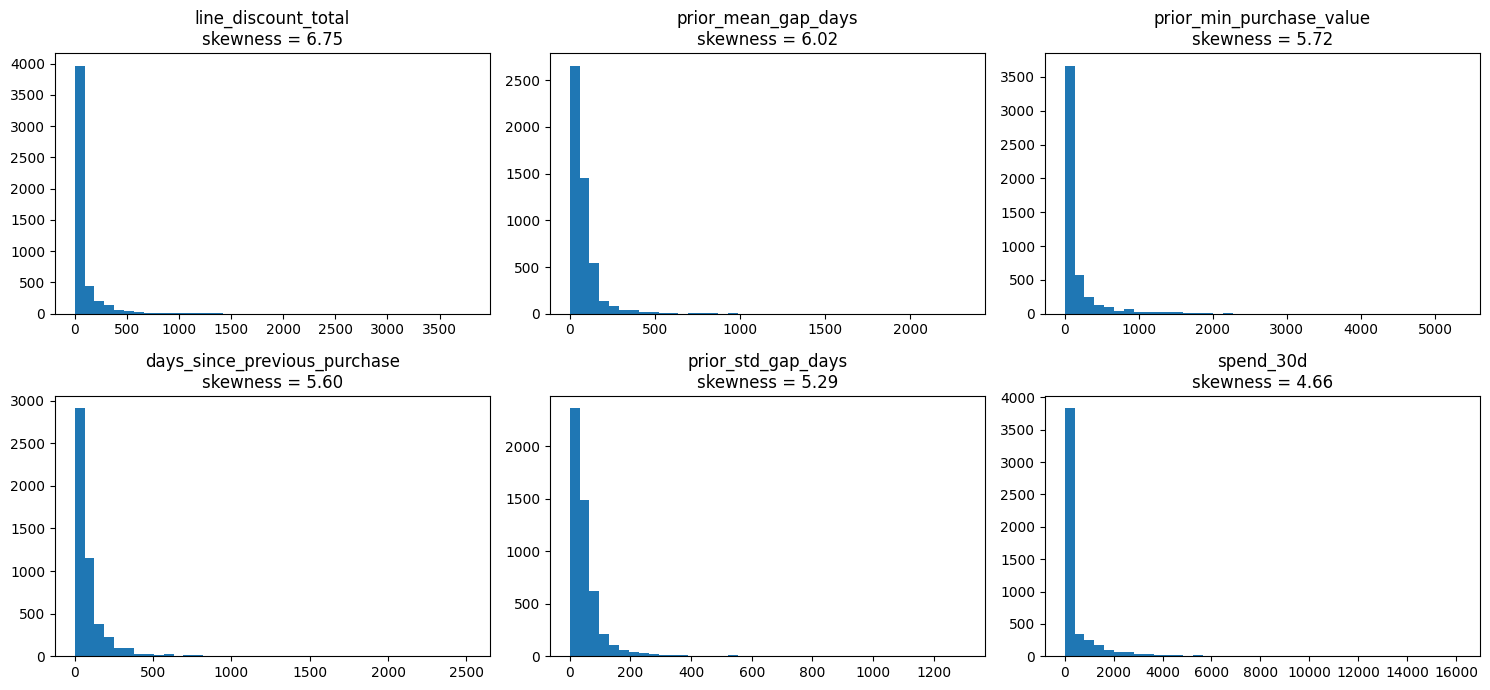


Largest values of line_discount_total


,id,customer_id,purchase_date,line_discount_total
3408,10003996,807493,2020-10-02,3794.51
1808,10002107,400536,2019-09-01,3720.00
3802,10004460,770941,2021-09-08,3704.89
2376,10002779,531725,2022-09-20,3434.18
5542,10006514,849644,2021-01-11,3386.82



Largest values of prior_mean_gap_days


,id,customer_id,purchase_date,prior_mean_gap_days
3987,10004689,871761,2022-10-22,2324.0
4008,10004715,495202,2020-09-08,1435.0
5552,10006524,273298,2019-04-30,1284.0
3068,10003590,128695,2020-12-21,1057.0
5633,10006619,805495,2018-07-07,986.0



Largest values of prior_min_purchase_value


,id,customer_id,purchase_date,prior_min_purchase_value
2250,10002626,823441,2018-09-08,5340.24
3027,10003546,683049,2021-12-17,4935.79
2960,10003466,161053,2018-09-14,4718.65
5543,10006515,952237,2022-05-07,4608.71
5599,10006581,322897,2021-11-06,4435.66


... (2 outputs left out)


Largest values of prior_std_gap_days


,id,customer_id,purchase_date,prior_std_gap_days
2459,10002879,519991,2020-10-27,1303.197798
5594,10006575,519991,2020-12-21,1065.792819
5499,10006464,161053,2022-09-17,1013.284017
4026,10004736,519991,2022-08-14,915.749010
3543,10004152,273298,2019-12-03,873.276875



Largest values of spend_30d


,id,customer_id,purchase_date,spend_30d
3436,10004025,942149,2016-10-22,16165.89
3778,10004432,755628,2022-08-13,11355.22
6247,10007337,942149,2016-10-28,11339.21
2064,10002412,755628,2022-08-08,11296.79
1309,10001531,540086,2018-01-12,11252.72


In [6]:
top_columns = (
    outlier_report["absolute_skewness"]
    .sort_values(ascending=False)
    .head(6)
    .index
)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for column, axis in zip(top_columns, axes.flat):
    axis.hist(numeric_data[column].dropna(), bins=40)
    axis.set_title(
        f"{column}\nskewness = {outlier_report.loc[column, 'skewness']:.2f}"
    )
plt.tight_layout()
plt.show()

for column in top_columns:
    largest = extras_dev[["id", "customer_id", "purchase_date"]].copy()
    largest[column] = numeric_data[column]
    print(f"\nLargest values of {column}")
    display(largest.nlargest(5, column))

# <font color='#2E86C1' size=6>**6. What do the algorithms actually flag?**</font> <a class="anchor" id="flags"></a>

IQR, Isolation Forest and LOF are compared on the same development rows. A 3% rate is used for the multivariate methods only to make their groups comparable. The target summaries reveal whether a method mainly selects useful high-value customers.

[Back to TOC](#toc)

In [7]:
def method_flags(features, numeric_features):
    available = [column for column in numeric_features if column in features.columns]
    iqr_count = pd.Series(0, index=features.index)

    for column in available:
        values = features[column]
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr > 0:
            flag = values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)
            iqr_count += flag.fillna(False).astype(int)

    scaler = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
    ])
    matrix = scaler.fit_transform(features[available])

    forest = IsolationForest(contamination=0.03, random_state=42)
    lof = LocalOutlierFactor(contamination=0.03)

    return pd.DataFrame({
        "IQR (3+ columns)": iqr_count.ge(3),
        "Isolation Forest": forest.fit_predict(matrix) == -1,
        "LOF": lof.fit_predict(matrix) == -1,
    }, index=features.index)

classification_flags = method_flags(X_dev, numeric_columns)

print("Rows flagged by each method")
display(classification_flags.mean().mul(100).round(2).rename("flagged_%"))
print("Pairwise overlap in rows")
display(classification_flags.astype(int).T.dot(classification_flags.astype(int)))

target_profiles = []
for method in classification_flags:
    flag = classification_flags[method]
    target_profiles.append({
        "method": method,
        "repeat rate — flagged": y_dev[flag].mean(),
        "repeat rate — other rows": y_dev[~flag].mean(),
    })
display(pd.DataFrame(target_profiles).set_index("method").round(3))

Rows flagged by each method


IQR (3+ columns)    25.26
Isolation Forest     3.01
LOF                  3.01
Name: flagged_%, dtype: float64

Pairwise overlap in rows


,IQR (3+ columns),Isolation Forest,LOF
IQR (3+ columns),1269,151,86
Isolation Forest,151,151,21
LOF,86,21,151


,repeat rate — flagged,repeat rate — other rows
method,,
IQR (3+ columns),0.774,0.474
Isolation Forest,0.868,0.540
LOF,0.563,0.549


# <font color='#2E86C1' size=6>**7. Temporal validation setup**</font> <a class="anchor" id="cv"></a>

Both tasks use five expanding-window folds with the same 90-day gap as the project pipeline. This estimates performance on future purchases and keeps fitted preprocessing out of validation data.

[Back to TOC](#toc)

In [8]:
def prepare_task(task, module, model_builder):
    prepared = prepare_task_data(config, task)
    features, target, row_info = prepared["X_dev"], prepared["y_dev"], prepared["extras_dev"]

    features = features.reset_index(drop=True)
    target = target.reset_index(drop=True)
    row_info = row_info.reset_index(drop=True)
    folds = temporal_folds(
        row_info[data_cfg["date_column"]],
        config["cv"]["n_splits"],
        config["cv"]["gap_days"],
    )

    return {
        "task": task,
        "X": features,
        "y": target,
        "folds": folds,
        "preprocessing": prepared["preprocessing_config"],
        "model_builder": model_builder,
        "metric": config[task]["selection_metric"],
    }

task_data = {
    "classification": prepare_task(
        "classification", classification_prep, build_classifier
    ),
    "regression": prepare_task(
        "regression", regression_prep, build_regressor
    ),
}

for task, data in task_data.items():
    print(task, "development rows:", len(data["X"]))

classification development rows: 5024
regression development rows: 2659


# <font color='#2E86C1' size=6>**8. Compare transformations**</font> <a class="anchor" id="transformations"></a>

`log1p` is fitted only to non-negative columns whose training-fold skewness exceeds 2. Winsorisation learns its limits from each training fold. These are compared with no change and robust scaling.

[Back to TOC](#toc)

**Order:** history fill → imputation and row bounds in original units → `log1p`/winsorisation → scaling. Skewness and quantiles are learned on the imputed training fold only. Clipping/logging can alter identities in model space; formulas and row limits are never evaluated in that space.

In [9]:
# Shared sklearn transformers operate on the numeric array AFTER bounded imputation.
from src.outliers import SkewLog1p, Winsorizer


In [10]:
def transformation_results(data):
    task = data["task"]
    prep_cfg = data["preprocessing"]
    numeric = prep_cfg["numeric_features"]
    recipes = {
        "No change": None,
        "log1p for skewed columns": SkewLog1p(numeric),
        "Winsorize 1%–99%": Winsorizer(numeric, 0.01, 0.99),
        "Winsorize 0.5%–99.5%": Winsorizer(numeric, 0.005, 0.995),
    }
    rows = []
    per_fold = {}

    for name, transformer in recipes.items():
        model = data["model_builder"](config[task]["model"])
        recipe = {**prep_cfg, "numeric_transform": transformer}
        pipeline = build_model_pipeline(recipe, model)
        scores = cross_validate_pipeline(
            pipeline, data["X"], data["y"], data["folds"], SCORING[task]
        )
        values = scores[f"validation_{data['metric']}"].to_numpy()
        per_fold[name] = values
        rows.append({
            "task": task, "method": name,
            "mean_score": values.mean(),
            "fold_std": values.std(ddof=1),
        })

    robust_cfg = {**prep_cfg, "scaler": "robust"}
    robust_scores = cross_validate_pipeline(
        build_model_pipeline(
            robust_cfg, data["model_builder"](config[task]["model"])
        ),
        data["X"], data["y"], data["folds"], SCORING[task],
    )
    robust_values = robust_scores[f"validation_{data['metric']}"].to_numpy()
    per_fold["Robust scaler"] = robust_values
    rows.append({
        "task": task, "method": "Robust scaler",
        "mean_score": robust_values.mean(),
        "fold_std": robust_values.std(ddof=1),
    })

    baseline = per_fold["No change"]
    for row in rows:
        comparison = paired_comparison(
            per_fold[row["method"]], baseline, task == "classification"
        )
        row["mean_advantage"] = comparison["mean_advantage"]
        row["std_difference"] = comparison["std_difference"]
        row["min_advantage"] = comparison["min_advantage"]
        row["max_advantage"] = comparison["max_advantage"]
        row["folds_better"] = comparison["folds_a_better"]
        row["consistent_gain"] = comparison["consistent_gain"]
    return rows

transformation_table = pd.DataFrame(
    transformation_results(task_data["classification"])
    + transformation_results(task_data["regression"])
)
display(transformation_table.round(4))

,task,method,mean_score,fold_std,mean_advantage,std_difference,min_advantage,max_advantage,folds_better,consistent_gain
0,classification,No change,0.7095,0.0168,0.0000,0.0000,0.0000,0.0000,0,False
1,classification,log1p for skewed columns,0.7160,0.0136,0.0065,0.0063,-0.0024,0.0131,4,False
2,classification,Winsorize 1%–99%,0.7155,0.0076,0.0060,0.0110,-0.0036,0.0239,3,False
3,classification,Winsorize 0.5%–99.5%,0.7160,0.0080,0.0065,0.0108,-0.0012,0.0251,3,False
4,classification,Robust scaler,0.7097,0.0157,0.0002,0.0023,-0.0036,0.0024,3,False
5,regression,No change,1937.3293,160.5946,0.0000,0.0000,-0.0000,-0.0000,0,False
6,regression,log1p for skewed columns,1937.2519,160.2276,0.0774,0.5392,-0.5835,0.7844,3,False
7,regression,Winsorize 1%–99%,1938.9741,160.9850,-1.6448,2.3945,-5.6551,0.2102,1,False
8,regression,Winsorize 0.5%–99.5%,1937.0569,159.0847,0.2724,1.7738,-1.8883,2.9954,2,False
9,regression,Robust scaler,1936.7117,161.4682,0.6176,0.9242,0.1300,2.2633,5,True


# <font color='#2E86C1' size=6>**9. Compare row-removal methods**</font> <a class="anchor" id="removal"></a>

Each detector sees only a training fold. It may remove rows from that fold, but the following validation period is left complete. A method is only accepted if its average advantage is larger than twice its standard error.

[Back to TOC](#toc)

**Comparison policy:** paired differences are descriptive. We report the mean, standard deviation, range and folds won. Overlapping temporal folds are dependent: these are not confidence intervals or significance tests. `consistent_gain` means strict improvement on every fold (at least two), a conservative screening heuristic; magnitude, domain reasoning and complexity still matter.

In [11]:
def scaled_numeric_matrix(features, columns):
    available = [column for column in columns if column in features.columns]
    scaler = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
    ])
    return scaler.fit_transform(features[available])


def rows_to_remove(features, numeric, method):
    if method == "No removal":
        return np.zeros(len(features), dtype=bool)

    if method == "IQR (3+ columns)":
        return method_flags(features, numeric)[method].to_numpy()

    matrix = scaled_numeric_matrix(features, numeric)

    if method == "Isolation Forest":
        return IsolationForest(
            contamination=0.03, random_state=42
        ).fit_predict(matrix) == -1

    if method == "LOF":
        return LocalOutlierFactor(contamination=0.03).fit_predict(matrix) == -1

    if method == "KNN distance":
        distances = NearestNeighbors(n_neighbors=11).fit(matrix).kneighbors(matrix)[0]
        score = distances[:, 1:].mean(axis=1)
        return score >= np.quantile(score, 0.97)

    if method == "K-Means distance":
        kmeans = KMeans(n_clusters=10, n_init=10, random_state=42).fit(matrix)
        score = np.linalg.norm(
            matrix - kmeans.cluster_centers_[kmeans.labels_], axis=1
        )
        return score >= np.quantile(score, 0.97)

    if method == "DBSCAN":
        distances = NearestNeighbors(n_neighbors=10).fit(matrix).kneighbors(matrix)[0]
        epsilon = np.quantile(distances[:, -1], 0.97)
        return DBSCAN(eps=epsilon, min_samples=10).fit_predict(matrix) == -1

    if method == "SOM distance":
        som = MiniSom(
            10, 10, matrix.shape[1], sigma=1, learning_rate=0.5, random_seed=42
        )
        som.random_weights_init(matrix)
        som.train_random(matrix, 1000)
        weights = som.get_weights()
        score = np.array([
            np.linalg.norm(row - weights[som.winner(row)]) for row in matrix
        ])
        return score >= np.quantile(score, 0.97)

    raise ValueError(f"Unknown method: {method}")

In [12]:
def evaluate_removal(data, method):
    task = data["task"]
    numeric = data["preprocessing"]["numeric_features"]
    scores = []
    removed = []

    for train_positions, validation_positions in data["folds"]:
        X_train = data["X"].iloc[train_positions]
        y_train = data["y"].iloc[train_positions]
        remove = rows_to_remove(X_train, numeric, method)
        removed.append(remove.mean() * 100)

        pipeline = build_model_pipeline(
            data["preprocessing"],
            data["model_builder"](config[task]["model"]),
        )
        pipeline.fit(X_train.loc[~remove], y_train.loc[~remove])
        predictions = pipeline.predict(data["X"].iloc[validation_positions])

        if task == "classification":
            score = accuracy_score(data["y"].iloc[validation_positions], predictions)
        else:
            score = mean_squared_error(
                data["y"].iloc[validation_positions], predictions
            ) ** 0.5
        scores.append(score)

    return np.array(scores), np.mean(removed)


removal_methods = [
    "No removal", "IQR (3+ columns)", "Isolation Forest", "LOF",
    "KNN distance", "K-Means distance", "DBSCAN", "SOM distance",
]
removal_rows = []

for task, data in task_data.items():
    results = {
        method: evaluate_removal(data, method) for method in removal_methods
    }
    baseline = results["No removal"][0]

    for method, (scores, removed_percent) in results.items():
        comparison = paired_comparison(
            scores, baseline, task == "classification"
        )
        removal_rows.append({
            "task": task,
            "method": method,
            "mean_score": scores.mean(),
            "fold_std": scores.std(ddof=1),
            "removed_%": removed_percent,
            "mean_advantage": comparison["mean_advantage"],
            "std_difference": comparison["std_difference"],
            "min_advantage": comparison["min_advantage"],
            "max_advantage": comparison["max_advantage"],
            "folds_better": comparison["folds_a_better"],
            "consistent_gain": comparison["consistent_gain"],
        })

removal_table = pd.DataFrame(removal_rows)
display(removal_table.round(4))

,task,method,mean_score,fold_std,removed_%,mean_advantage,std_difference,min_advantage,max_advantage,folds_better,consistent_gain
0,classification,No removal,0.7095,0.0168,0.0000,0.0000,0.0000,0.0000,0.0000,0,False
1,classification,IQR (3+ columns),0.7083,0.0151,23.8234,-0.0012,0.0127,-0.0203,0.0119,3,False
2,classification,Isolation Forest,0.7066,0.0160,3.0327,-0.0029,0.0062,-0.0119,0.0036,2,False
3,classification,LOF,0.7119,0.0211,3.0327,0.0024,0.0058,-0.0072,0.0084,4,False
4,classification,KNN distance,0.7121,0.0199,3.0327,0.0026,0.0091,-0.0060,0.0167,2,False
5,classification,K-Means distance,0.7062,0.0187,3.0327,-0.0033,0.0049,-0.0096,0.0036,1,False
6,classification,DBSCAN,0.7078,0.0196,1.7651,-0.0017,0.0059,-0.0096,0.0072,1,False
7,classification,SOM distance,0.7090,0.0229,3.0327,-0.0005,0.0090,-0.0143,0.0108,2,False
8,regression,No removal,1937.3293,160.5946,0.0000,0.0000,0.0000,-0.0000,-0.0000,0,False
9,regression,IQR (3+ columns),2164.8850,159.8084,23.9727,-227.5556,110.3138,-311.4303,-34.1166,0,False


# <font color='#2E86C1' size=6>**10. DBSCAN sensitivity**</font> <a class="anchor" id="dbscan"></a>

DBSCAN needs an `eps` choice. The table shows how several reasonable choices change the result on the same development data. A stable natural cluster structure would not change this sharply.

[Back to TOC](#toc)

In [13]:
matrix = scaled_numeric_matrix(X_dev, numeric_columns)
neighbour_distances = (
    NearestNeighbors(n_neighbors=10).fit(matrix).kneighbors(matrix)[0][:, -1]
)
dbscan_rows = []

for quantile in [0.90, 0.95, 0.97, 0.99]:
    epsilon = np.quantile(neighbour_distances, quantile)
    labels = DBSCAN(eps=epsilon, min_samples=10).fit_predict(matrix)
    cluster_count = len(set(labels)) - int(-1 in labels)
    dbscan_rows.append({
        "k-distance quantile": quantile,
        "eps": epsilon,
        "noise_%": np.mean(labels == -1) * 100,
        "clusters": cluster_count,
    })

display(pd.DataFrame(dbscan_rows).round(3))

,k-distance quantile,eps,noise_%,clusters
0,0.90,4.935,5.812,3
1,0.95,6.516,2.607,1
2,0.97,7.928,1.572,1
3,0.99,11.677,0.378,1


# <font color='#2E86C1' size=6>**11. Method-by-method judgement**</font> <a class="anchor" id="judgement"></a>

The following describes the full rerun above, with fold-local history and transforms after bounded imputation.

| Method | Observed result and decision |
|---|---|
| Logical consistency rules | Retain: they address impossible combinations from feature definitions. Their purpose is data validity, not maximising CV scores. |
| IQR removal (3+ columns) | Regression RMSE worsens by 227.56 euros and is worse on all five folds; about 24% of training rows are removed. Keep IQR as a diagnostic. |
| `log1p` | Classification accuracy 0.7160 vs 0.7095, better on 4/5 folds. Regression gain only 0.08 euros, better on 3/5. A candidate with a mixed classification fold result, not demonstrated significance. Leave off. |
| Winsorisation | Classification gains about 0.0060–0.0065 accuracy, better on 3/5 folds. Regression: 1%–99% is 1.64 euros worse; 0.5%–99.5% gains 0.27 euros on 2/5 folds. Leave off. |
| Robust scaling | Classification gains 0.0002 on 3/5 folds. Regression improves on 5/5 folds, but by only 0.62 euros (about 0.032% of baseline RMSE). It passes the consistency screen; that tiny magnitude does not motivate changing the configured scaler. |
| Isolation Forest removal | Regression improves by 21.60 euros on average, on 3/5 folds, with fold advantages ranging from -68.85 to +183.52 euros. Classification worsens by 0.0029. Mixed results; no automatic removal. |
| LOF / KNN distance / DBSCAN / K-Means / SOM | None improves on all folds. Detector thresholds and distance definitions are modelling choices, not proof that a purchase is wrong. Keep for investigation. |

These are descriptive comparisons across dependent temporal folds, not confidence intervals or statistical tests. Passing the all-fold screen does not replace judgement about practical magnitude and complexity.

[Back to TOC](#toc)


# <font color='#2E86C1' size=6>**Final decision**</font> <a class="anchor" id="decision"></a>

1. Retain domain consistency corrections and plausible extreme observations.
2. Keep statistical row removal and capping off. No removal method improved on every temporal fold; IQR removal particularly harmed regression.
3. Keep the configured scalers and no log transform. Robust scaling's regression gain is consistent but only 0.62 euros; `log1p` is a classification candidate (+0.0065 accuracy, 4/5 folds), with one fold worse. These results do not establish superiority or equivalence.
4. Use IQR and Isolation Forest for investigation, not automatic deletion.

Every validation row and test.csv row is retained. These comparisons used development folds only; the locked period was not scored. The next improvement experiments are separate from these corrections.

[Back to TOC](#toc)
